# 02c — Coefficient de température du combustible (effet Doppler)

**Question** : quand le combustible s'échauffe, que devient la réactivité, et par quel mécanisme ?

Le coefficient de température du combustible, ou **coefficient Doppler**,

$$\alpha_D = \frac{\partial \rho}{\partial T_\text{comb}} \quad (\text{pcm/K}),$$

est le premier contre-effet de sûreté d'un réacteur : la chaleur est produite **dans** le combustible, qui s'échauffe
donc immédiatement lors d'une hausse de puissance, bien avant que l'eau ne s'échauffe à son tour (notebook 02b).

**Plan**
1. Réactivité en fonction de la température du combustible, loi en $\sqrt{T}$, coefficient Doppler.
2. Le mécanisme : élargissement des résonances de l'U-238 et augmentation des captures.
3. Interprétation et limites.

## 0. Méthode et choix des températures

On fait varier la température du combustible UO₂ (4 %), toutes choses égales par ailleurs : eau à 580 K et
1000 ppm de bore, gaine à 600 K.

**Contrainte des données nucléaires.** La bibliothèque ENDF/B-VIII.0 utilisée fournit les sections efficaces de l'U-238
à six températures : 250, 294, 600, 900, 1200 et 2500 K. Entre deux températures tabulées, OpenMC **interpole
linéairement** en température (méthode `interpolation`). Or l'effet Doppler n'est pas linéaire en température (on va
voir qu'il suit plutôt $\sqrt{T}$) : des points intermédiaires refléteraient en partie l'interpolation et non la
physique. On se limite donc aux **températures tabulées** : 294, 600, 900, 1200 et 2500 K.

Chaque point utilise 5 millions d'histoires (incertitude d'environ 25 pcm sur ρ), et les résultats déjà calculés sont
réutilisés si les entrées n'ont pas changé (`src/calcul.py`).

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc
import openmc.data
import h5py

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))
from src.style import appliquer_style, COULEURS
appliquer_style()
from src.modeles import modele_cellule_crayon
from src.calcul import calculer_k, reactivite_pcm

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "02c_doppler"
DOSSIER_RESULTATS = RACINE / "results" / "02c_doppler"   # figures et tableaux de ce notebook
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)
STATISTIQUE = dict(particules=20_000, generations=300, inactives=50, graine=1)   # 5 M d'histoires actives

# Vérification : températures disponibles pour l'U-238 dans la bibliothèque
bibliotheque = openmc.data.DataLibrary.from_xml(os.environ["OPENMC_CROSS_SECTIONS"])
with h5py.File(bibliotheque.get_by_material("U238")["path"]) as f:
    temperatures_u238 = sorted(f["U238"]["kTs"].keys(), key=lambda t: float(t[:-1]))
print("Températures tabulées de l'U-238 :", temperatures_u238)

Températures tabulées de l'U-238 : ['250K', '294K', '600K', '900K', '1200K', '2500K']


### Tallies : voir le mécanisme

En plus de k, on mesure dans le combustible :
- le **flux** autour de la grande résonance de capture de l'U-238 à **6,67 eV** (250 groupes entre 5,5 et 8 eV) ;
- le **taux de capture radiative (n,γ) de l'U-238**, découpé en trois domaines : thermique (< 0,625 eV), résonances
  (0,625 eV à 100 keV) et rapide (> 100 keV).

In [2]:
BORNES_RESONANCE = np.linspace(5.5, 8.0, 251)          # eV
BORNES_DOMAINES = [1e-5, 0.625, 1e5, 20e6]             # thermique / résonances / rapide
NOMS_DOMAINES = ["thermique", "résonances", "rapide"]


def ajouter_tallies(modele, cellules):
    filtre_comb = openmc.CellFilter([cellules["combustible"]])
    flux = openmc.Tally(name="flux_resonance")
    flux.filters = [filtre_comb, openmc.EnergyFilter(BORNES_RESONANCE)]
    flux.scores = ["flux"]
    capture = openmc.Tally(name="capture_U238")
    capture.filters = [filtre_comb, openmc.EnergyFilter(BORNES_DOMAINES)]
    capture.nuclides = ["U238"]
    capture.scores = ["(n,gamma)"]
    modele.tallies = openmc.Tallies([flux, capture])


def lire_tallies(statepoint):
    with openmc.StatePoint(statepoint) as sp:
        flux = sp.get_tally(name="flux_resonance").mean.ravel()
        capture = sp.get_tally(name="capture_U238")
        return flux, capture.mean.ravel(), capture.std_dev.ravel()

## 1. Réactivité en fonction de la température du combustible

In [3]:
temperatures = [294.0, 600.0, 900.0, 1200.0, 2500.0]   # K, toutes tabulées

lignes, flux_resonance = [], {}
for T in temperatures:
    modele, cellules = modele_cellule_crayon(enrichissement=4.0, bore_ppm=1000, t_combustible=T, **STATISTIQUE)
    ajouter_tallies(modele, cellules)
    r = calculer_k(modele, DOSSIER_CALCUL / f"T_comb_{T:.0f}")
    rho, s_rho = reactivite_pcm(r["k"], r["sigma"])
    flux, capture, s_capture = lire_tallies(r["statepoint"])
    flux_resonance[T] = flux
    ligne = {"T_combustible_K": T, "k_inf": r["k"], "sigma": r["sigma"], "rho_pcm": rho, "sigma_rho_pcm": s_rho}
    for nom, c, s in zip(NOMS_DOMAINES, capture, s_capture):
        ligne[f"capture_U238_{nom}"], ligne[f"sigma_capture_{nom}"] = c, s
    lignes.append(ligne)
    print(f"T = {T:6.0f} K   k∞ = {r['k']:.5f} ± {r['sigma']:.5f}   ρ = {rho:7.0f} ± {s_rho:.0f} pcm"
          + ("   (résultat réutilisé)" if r["reutilise"] else ""))

df = pd.DataFrame(lignes)
df.to_csv(DOSSIER_RESULTATS / "doppler.csv", index=False)

T =    294 K   k∞ = 1.28909 ± 0.00041   ρ =   22426 ± 24 pcm   (résultat réutilisé)
T =    600 K   k∞ = 1.27482 ± 0.00041   ρ =   21558 ± 25 pcm   (résultat réutilisé)


T =    900 K   k∞ = 1.26488 ± 0.00043   ρ =   20941 ± 27 pcm   (résultat réutilisé)
T =   1200 K   k∞ = 1.25658 ± 0.00043   ρ =   20419 ± 27 pcm   (résultat réutilisé)


T =   2500 K   k∞ = 1.22615 ± 0.00044   ρ =   18444 ± 29 pcm   (résultat réutilisé)


### Loi en $\sqrt{T}$

L'agitation thermique des noyaux d'U-238 étale les résonances sur une largeur en énergie, dite largeur Doppler,
proportionnelle à $\sqrt{T}$ (on la calcule en partie 2). On s'attend donc à une réactivité de la forme

$$\rho(T) \approx a + b\,\sqrt{T} \qquad \Rightarrow \qquad \alpha_D = \frac{d\rho}{dT} = \frac{b}{2\sqrt{T}}$$

Le coefficient Doppler serait alors **moins négatif à haute température**, en $1/\sqrt{T}$. On compare cet ajustement à
une simple droite en $T$, avec le $\chi^2$ réduit (comme dans le notebook 02a).

In [4]:
T = df.T_combustible_K.values
rho, s_rho = df.rho_pcm.values, df.sigma_rho_pcm.values

ajustements = {}
for nom, x in {"droite en T": T, "droite en √T": np.sqrt(T)}.items():
    coefs, cov = np.polyfit(x, rho, 1, w=1 / s_rho, cov="unscaled")
    residus = (rho - np.polyval(coefs, x)) / s_rho
    chi2 = np.sum(residus**2) / (len(T) - 2)
    ajustements[nom] = (coefs, cov, residus, chi2)
    print(f"{nom:14s} : χ² réduit = {chi2:6.1f}   résidus (σ) = {np.round(residus, 1)}")

(b, a), cov, _, chi2 = ajustements["droite en √T"]
birge = max(1.0, np.sqrt(chi2))


def alpha_doppler(T_ref):
    # α_D = b / (2√T), incertitude propagée depuis celle de b (élargie par le facteur de Birge)
    return b / (2 * np.sqrt(T_ref)), np.sqrt(cov[0, 0]) * birge / (2 * np.sqrt(T_ref))


print()
for T_ref in (600, 900, 1200):
    val, err = alpha_doppler(T_ref)
    print(f"Coefficient Doppler à {T_ref:4d} K : α_D = {val:5.2f} ± {err:.2f} pcm/K")

droite en T    : χ² réduit =   71.3   résidus (σ) = [10.1 -3.3 -6.3 -6.   5.1]
droite en √T   : χ² réduit =    4.4   résidus (σ) = [-1.3 -0.6  1.2  2.5 -1.8]

Coefficient Doppler à  600 K : α_D = -2.46 ± 0.05 pcm/K
Coefficient Doppler à  900 K : α_D = -2.01 ± 0.04 pcm/K
Coefficient Doppler à 1200 K : α_D = -1.74 ± 0.03 pcm/K


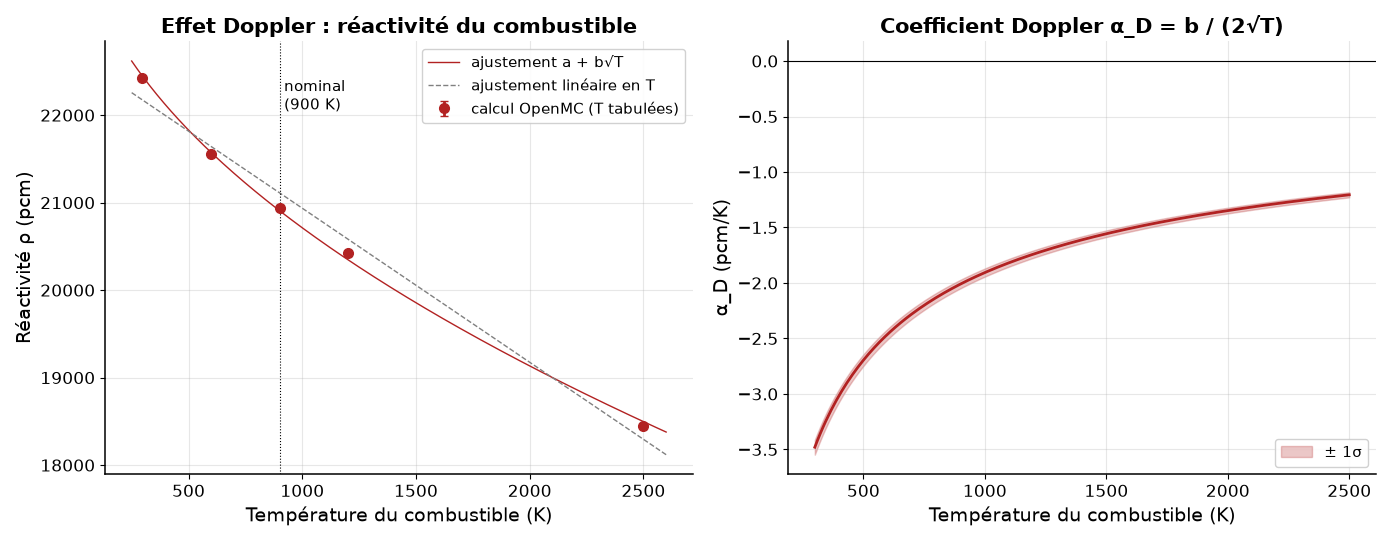

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

T_fin = np.linspace(250, 2600, 300)
ax1.errorbar(T, rho, yerr=s_rho, fmt="o", color="firebrick", capsize=3, label="calcul OpenMC (T tabulées)")
ax1.plot(T_fin, np.polyval(ajustements["droite en √T"][0], np.sqrt(T_fin)), color="firebrick", lw=1,
         label="ajustement a + b√T")
ax1.plot(T_fin, np.polyval(ajustements["droite en T"][0], T_fin), "--", color="gray", lw=1,
         label="ajustement linéaire en T")
ax1.axvline(900, color="k", ls=":", lw=0.8)
ax1.text(920, rho.max(), "nominal\n(900 K)", fontsize=11, va="top")
ax1.set_xlabel("Température du combustible (K)")
ax1.set_ylabel("Réactivité ρ (pcm)")
ax1.set_title("Effet Doppler : réactivité du combustible")
ax1.legend(fontsize=11)

T_alpha = np.linspace(300, 2500, 200)
val, err = alpha_doppler(T_alpha)
ax2.plot(T_alpha, val, color="firebrick")
ax2.fill_between(T_alpha, val - err, val + err, color="firebrick", alpha=0.25, label="± 1σ")
ax2.axhline(0, color="k", lw=0.8)
ax2.set_xlabel("Température du combustible (K)")
ax2.set_ylabel("α_D (pcm/K)")
ax2.set_title("Coefficient Doppler α_D = b / (2√T)")
ax2.legend(fontsize=11)

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "doppler.png", bbox_inches="tight")
plt.show()

**Lecture.**
- La droite en $T$ est rejetée ($\chi^2$ réduit ≈ 71, résidus systématiques de 3 à 10σ) : la réactivité n'est pas
  linéaire en température.
- La loi en $\sqrt{T}$ suit beaucoup mieux les points ($\chi^2$ réduit ≈ 4,4), mais pas parfaitement (un résidu
  atteint 2,5σ) : c'est une **approximation**, pas une loi exacte. L'élargissement Doppler varie en $\sqrt{T}$, mais
  son effet sur les captures passe par l'autoprotection, qui n'est pas strictement proportionnelle. L'incertitude
  sur $\alpha_D$ est donc élargie par le facteur de Birge ($\sqrt{4{,}4} \approx 2{,}1$).
- **À 900 K, $\alpha_D \approx -2{,}0$ pcm/K.** Le coefficient est plus négatif à basse température (−2,5 pcm/K à
  600 K) qu'à haute température (−1,7 pcm/K à 1200 K).

## 2. Le mécanisme : élargissement Doppler des résonances

Une résonance de capture est un pic très étroit de section efficace, centré sur une énergie précise **dans le
référentiel du noyau** (6,67 eV pour la première grande résonance de l'U-238). Les noyaux d'UO₂ n'étant pas immobiles
mais agités thermiquement, l'énergie relative neutron-noyau est étalée : vue par les neutrons, la résonance devient
**plus basse et plus large**. Sa largeur Doppler vaut, pour une résonance d'énergie $E_0$ sur un noyau de masse $A$ :

$$\Gamma_D = \sqrt{\frac{4\, E_0\, k_B T}{A}}$$

In [6]:
k_B = 8.617333e-5   # eV/K
E0, A = 6.67, 238.05
for T_ in (294, 900, 2500):
    print(f"T = {T_:4d} K : largeur Doppler Γ_D = {np.sqrt(4 * E0 * k_B * T_ / A) * 1e3:5.1f} meV")
print("(largeur naturelle de la résonance à 6,67 eV : de l'ordre de 25 meV)")

T =  294 K : largeur Doppler Γ_D =  53.3 meV
T =  900 K : largeur Doppler Γ_D =  93.2 meV
T = 2500 K : largeur Doppler Γ_D = 155.4 meV
(largeur naturelle de la résonance à 6,67 eV : de l'ordre de 25 meV)


L'« aire » de la résonance (l'intégrale de la section efficace sur l'énergie) est conservée par l'élargissement. Alors
pourquoi les captures augmentent-elles ? À cause de l'**autoprotection** (notebook 01) : au sommet d'une résonance,
la section efficace est si grande que les neutrons de cette énergie sont capturés dès la surface de la pastille, et le
flux s'effondre à l'intérieur. Les captures sont limitées par le **manque de neutrons**, pas par la section efficace.
Quand la résonance s'élargit, ses ailes s'étendent sur des énergies où le flux n'est pas encore effondré : il y a plus
de neutrons disponibles à capturer. Le creux de flux doit donc **s'élargir**.

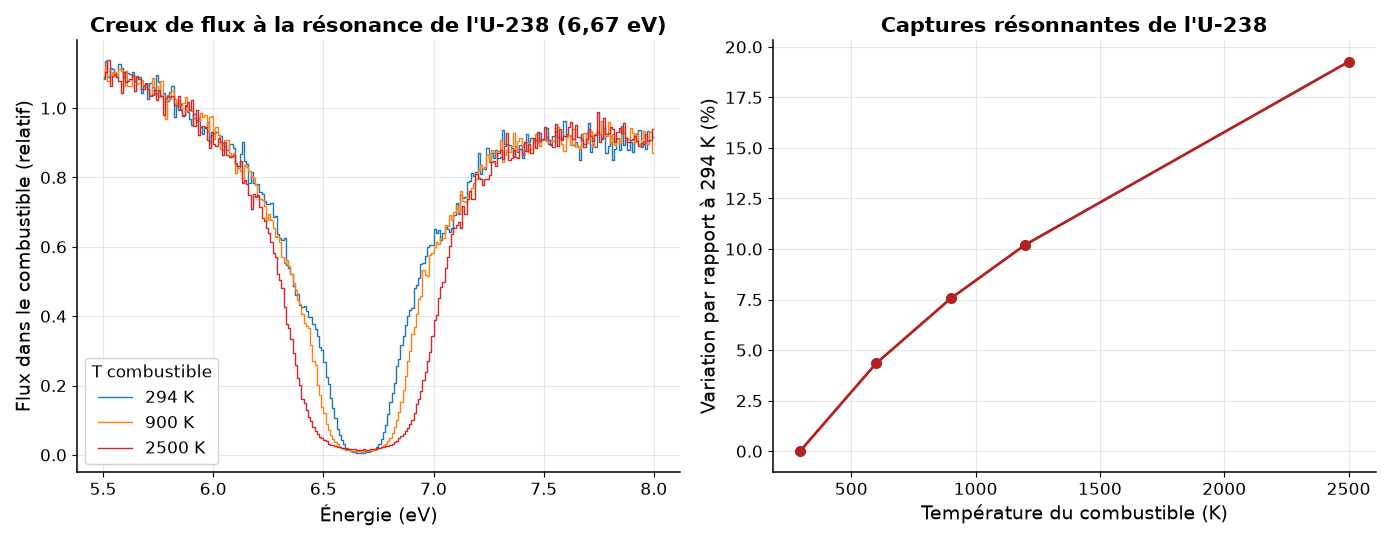

,T (K),captures U-238 thermique,captures U-238 résonances,captures U-238 rapide
0,294.000000,0.0469,0.1974,0.0137
1,600.000000,0.0463,0.2059,0.0137
2,900.000000,0.0459,0.2123,0.0137
3,1200.000000,0.0455,0.2175,0.0137
4,2500.000000,0.0442,0.2354,0.0137


In [7]:
E_res = 0.5 * (BORNES_RESONANCE[:-1] + BORNES_RESONANCE[1:])
dE = np.diff(BORNES_RESONANCE)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for T_, couleur in [(294.0, "tab:blue"), (900.0, "tab:orange"), (2500.0, "tab:red")]:
    # Flux par eV, normalisé par sa valeur moyenne sur les bords de la fenêtre (hors résonance)
    phi = flux_resonance[T_] / dE
    reference = np.mean(np.r_[phi[:20], phi[-20:]])
    ax1.step(E_res, phi / reference, where="mid", color=couleur, lw=1, label=f"{T_:.0f} K")
ax1.set_xlabel("Énergie (eV)")
ax1.set_ylabel("Flux dans le combustible (relatif)")
ax1.set_title("Creux de flux à la résonance de l'U-238 (6,67 eV)")
ax1.legend(title="T combustible")

reso = df.capture_U238_résonances.values
s_reso = df.sigma_capture_résonances.values
ax2.errorbar(T, (reso / reso[0] - 1) * 100, yerr=s_reso / reso[0] * 100, fmt="o-", color="firebrick", capsize=3)
ax2.set_xlabel("Température du combustible (K)")
ax2.set_ylabel("Variation par rapport à 294 K (%)")
ax2.set_title("Captures résonnantes de l'U-238")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "mecanisme.png", bbox_inches="tight")
plt.show()

df_captures = df[["T_combustible_K"] + [f"capture_U238_{n}" for n in NOMS_DOMAINES]].copy()
df_captures.columns = ["T (K)"] + [f"captures U-238 {n}" for n in NOMS_DOMAINES]
df_captures.style.format({c: "{:.4f}" for c in df_captures.columns[1:]})

**Lecture.**
- **Creux de flux** (à gauche) : au centre de la résonance, le flux reste **quasi nul aux trois températures** : même
  élargie, la résonance est si absorbante que les neutrons de 6,67 eV ne pénètrent pas dans la pastille. Ce qui change,
  c'est la **largeur** du creux, nettement plus grande à 2500 K qu'à 294 K : les ailes de la résonance « mordent » sur
  des énergies voisines où le flux était auparavant presque intact.
- **Captures** (à droite et tableau, par neutron source) : entre 294 et 2500 K, les captures de l'U-238 dans le domaine
  des **résonances** augmentent d'environ 19 %. Dans le même temps, les captures **thermiques** baissent d'environ 6 % :
  moins de neutrons échappent aux résonances pendant leur ralentissement (le facteur antitrappe $p$ diminue), donc moins
  atteignent le domaine thermique. Les captures **rapides** ne changent pas : l'effet Doppler ne concerne que les
  résonances.

## 3. Interprétation et limites

- **Signe et ordre de grandeur.** Le coefficient Doppler est négatif, de quelques pcm/K, soit bien plus petit en
  valeur absolue que le coefficient du modérateur sans bore (notebook 02b). Mais il agit **instantanément** : c'est
  lui qui arrête en premier une excursion de puissance rapide (par exemple l'éjection accidentelle d'une grappe de
  commande), avant même que la chaleur n'ait traversé la gaine.
- **Loi en $\sqrt{T}$.** Le coefficient est plus fort à basse température : un réacteur froid est plus sensible à
  l'échauffement de son combustible qu'un réacteur en puissance.
- **Toujours négatif.** Contrairement au coefficient du modérateur, il ne peut pas changer de signe avec le bore : il
  vient des captures de l'U-238, toujours très majoritaire dans le combustible. Son intensité dépend un peu du spectre
  (donc du bore, de l'enrichissement, du burn-up), ce que nous n'avons pas étudié ici, mais il reste négatif : c'est une
  propriété intrinsèque des combustibles à uranium faiblement enrichi.

**Limites du modèle.**
- La pastille réelle n'est pas à température uniforme : le centre peut dépasser 1 200 K quand la surface est vers
  700 K (faible conductivité de l'UO₂). On utilise ici une **température effective** uniforme, une approximation
  courante en neutronique.
- Les températures sont limitées aux valeurs tabulées de la bibliothèque. Des données en multipôles fenêtrés (*windowed
  multipole*), qu'OpenMC sait utiliser mais que notre bibliothèque ne contient pas, permettraient de calculer les sections
  efficaces exactement à n'importe quelle température.

## 4. Bilan

- La réactivité baisse quand le combustible s'échauffe : c'est l'**effet Doppler**, dû à l'élargissement des résonances
  de capture de l'U-238 par l'agitation thermique des noyaux.
- La réactivité suit approximativement une loi en $\sqrt{T}$, et le coefficient Doppler, négatif, décroît en valeur
  absolue comme $1/\sqrt{T}$.
- Les tallies montrent le mécanisme : creux de flux à 6,67 eV plus large à chaud (le flux reste quasi nul au centre),
  et davantage de captures résonnantes dans l'U-238 (+19 % entre 294 et 2500 K).

Les notebooks 02a, 02b et 02c complètent l'étude de la cellule crayon. **Suite** : l'assemblage 17×17 (notebook 03).

## Sources

- Documentation OpenMC 0.16 : traitement de la température (`Settings.temperature`, méthode `interpolation`),
  <https://docs.openmc.org/>.
- P. Reuss, *Précis de neutronique*, EDP Sciences : effet Doppler, autoprotection, facteur antitrappe.